# 07 · Optimización del modelo ganador (K-means)

**Entrada:** decisiones del notebook 06 (ganador: **K-means**, $k = 3$; alternativa a revisar: $k = 5$).

## Qué se optimiza

| # | Pregunta | Sección |
|---|---|---|
| 1 | ¿Qué inicialización y cuántos reinicios garantizan la mejor solución de forma reproducible? | 2 |
| 2 | ¿Mejora una variante **robusta** (K-medoids, distancia euclidiana o Manhattan)? | 3 |
| 3 | ¿Los grupos dependen de las decisiones de preprocesamiento? | 4 |
| 4 | ¿Qué tan estable es **cada grupo** por separado? | 5 |
| 5 | ¿$k = 3$ o $k = 5$? ¿Qué partición describe mejor los patrones delictivos? | 6 |

Al final se ajusta y guarda el **modelo final**.

## 0. Configuración

In [1]:
import sys
import json
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_samples
from IPython.display import display

from src.utilidades import (RUTA_PROCESSED, RAIZ as RAIZ_PROY, COLOR, PALETA_CATEGORICA,
                            CMAP_DIVERGENTE, CODIGO_A_CORTO, configurar_estilo, subtitulo,
                            fuente, guardar_figura)
from src.modelos import (KMedoids, metricas_internas, estabilidad_bootstrap,
                         estabilidad_por_grupo, ordenar_grupos)

warnings.filterwarnings("ignore", category=UserWarning)
configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CARPETA_FIG = "07_optimizacion"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
RUTA_REPORTES = RAIZ_PROY / "outputs" / "reports"
with open(RUTA_REPORTES / "06_decisiones.json", encoding="utf-8") as f:
    dec06 = json.load(f)
SEMILLA = dec06["semilla"]
K_CANDIDATOS = [dec06["k_ganador"], dec06["k_alternativo_para_optimizacion"]]   # [3, 5]

X_df = pd.read_csv(RUTA_PROCESSED / "matrices" / f"{dec06['representacion']}.csv",
                   index_col=0, encoding="utf-8-sig")
X = X_df.values
NOMBRES = {**CODIGO_A_CORTO, "sexuales_agravados": "Sexuales agravados (3)"}
COLOR_GRUPO = [COLOR["azul"], COLOR["naranja"], COLOR["aqua"], COLOR["amarillo"],
               COLOR["magenta"], COLOR["verde"]]
print(f"Modelo ganador: {dec06['ganador']} · k candidatos: {K_CANDIDATOS}")
print(f"Representación: {dec06['representacion']} ({X.shape[0]} × {X.shape[1]})")

Modelo ganador: K-means · k candidatos: [3, 5]
Representación: R4b_agravados_agrupados (340 × 10)


## 1. Recordatorio: ¿cómo funciona K-means?

1. Se colocan $k$ centroides iniciales.
2. Cada municipio se asigna al centroide más cercano (distancia euclidiana).
3. Cada centroide se recalcula como el promedio de sus municipios.
4. Se repiten los pasos 2 y 3 hasta que las asignaciones no cambian.

El algoritmo minimiza la **inercia** (suma de distancias al cuadrado de cada municipio a su centroide), pero puede quedar atrapado en un **mínimo local** que depende de los centroides iniciales. Por eso se optimizan la **inicialización** y el **número de reinicios** (`n_init`): se ejecuta varias veces y se queda la solución de menor inercia.

## 2. Hiperparámetros: inicialización y número de reinicios

Para cada combinación se ajusta el modelo con **20 semillas distintas** y se mide:

- Qué porcentaje de corridas llega a la **mejor solución conocida** (obtenida con 3,000 reinicios).
- El **ARI mínimo** entre la partición de cada semilla y la mejor solución: ¿cambian los grupos según la semilla?

In [2]:
CONFIGS = [("k-means++", n) for n in [1, 10, 50, 100, 500, 1000]] + [("random", n) for n in [1, 10, 50, 100]]
filas = []
for k in K_CANDIDATOS:
    referencia = KMeans(k, n_init=3000, random_state=SEMILLA).fit(X)   # mejor solución conocida
    for init, n_init in CONFIGS:
        modelos = [KMeans(k, init=init, n_init=n_init, random_state=s).fit(X) for s in range(20)]
        inercias = np.array([m.inertia_ for m in modelos])
        filas.append({
            "k": k, "init": init, "n_init": n_init,
            "inercia_media": inercias.mean(), "inercia_max": inercias.max(),
            "% corridas en el óptimo": np.mean(np.isclose(inercias, referencia.inertia_)) * 100,
            "ARI_min_vs_óptimo": min(adjusted_rand_score(referencia.labels_, m.labels_) for m in modelos),
        })
hiper = pd.DataFrame(filas)
display(hiper)

,k,init,n_init,inercia_media,inercia_max,% corridas en el óptimo,ARI_min_vs_óptimo
0,3,k-means++,1,"1,705.402","1,706.624",5.000,0.900
1,3,k-means++,10,"1,704.804","1,704.960",65.000,0.981
2,3,k-means++,50,"1,704.768","1,704.768",100.000,1.000
3,3,k-means++,100,"1,704.768","1,704.768",100.000,1.000
4,3,k-means++,500,"1,704.768","1,704.768",100.000,1.000
5,3,k-means++,1000,"1,704.768","1,704.768",100.000,1.000
6,3,random,1,"1,705.501","1,706.624",10.000,0.900
7,3,random,10,"1,704.803","1,704.960",70.000,0.981
8,3,random,50,"1,704.770","1,704.806",95.000,0.991
9,3,random,100,"1,704.768","1,704.768",100.000,1.000


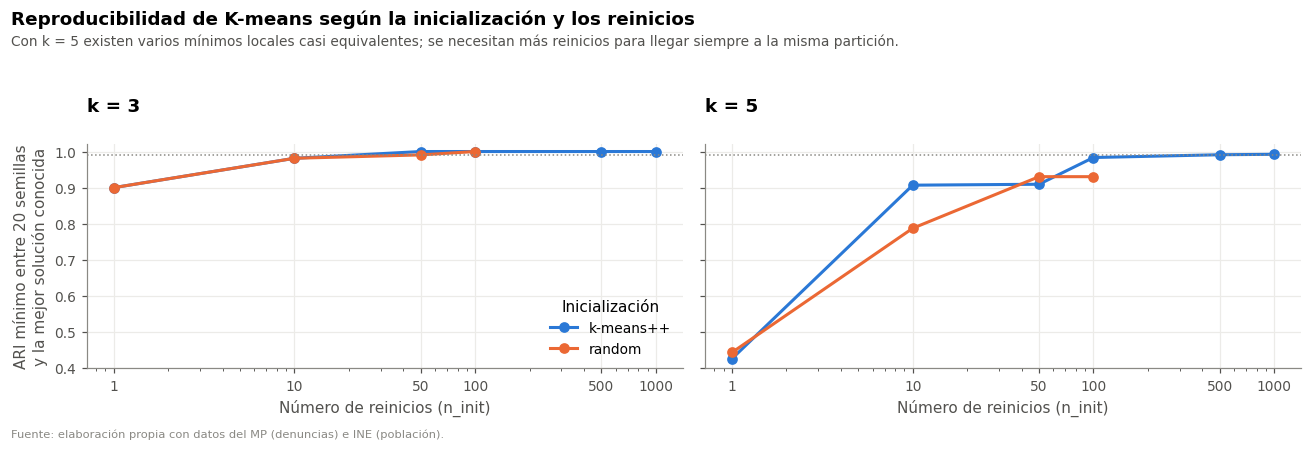

n_init para el modelo final: 500
n_init para análisis con bootstrap: 50


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, k in zip(axes, K_CANDIDATOS):
    for init, color in [("k-means++", COLOR["azul"]), ("random", COLOR["naranja"])]:
        d = hiper[(hiper["k"] == k) & (hiper["init"] == init)]
        ax.plot(d["n_init"], d["ARI_min_vs_óptimo"], marker="o", color=color, label=init)
    ax.axhline(0.99, color=COLOR["gris"], linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 50, 100, 500, 1000], ["1", "10", "50", "100", "500", "1000"])
    ax.set_ylim(0.4, 1.02)
    ax.set_xlabel("Número de reinicios (n_init)")
    ax.set_title(f"k = {k}")
axes[0].set_ylabel("ARI mínimo entre 20 semillas\ny la mejor solución conocida")
axes[0].legend(title="Inicialización", loc="lower right")
fig.suptitle("Reproducibilidad de K-means según la inicialización y los reinicios", x=0.01,
             ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.9, "Con k = 5 existen varios mínimos locales casi equivalentes; se necesitan más "
         "reinicios para llegar siempre a la misma partición.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
guardar_figura(fig, "01_hiperparametros", CARPETA_FIG)
plt.show()

# Regla: el menor n_init (k-means++) cuya partición coincide con la óptima (ARI ≥ 0.99) en todas las semillas, para ambos k
ok = hiper[(hiper["init"] == "k-means++") & (hiper["ARI_min_vs_óptimo"] >= 0.99)]
N_INIT_FINAL = int(ok.groupby("n_init")["k"].nunique().loc[lambda s: s == len(K_CANDIDATOS)].index.min())
N_INIT = 50   # para los análisis con cientos de remuestreos (ARI ≥ 0.91 con el óptimo y costo razonable)
print(f"n_init para el modelo final: {N_INIT_FINAL}")
print(f"n_init para análisis con bootstrap: {N_INIT}")

## 3. Variante robusta: K-medoids

K-medoids (PAM) usa como centro a un **municipio real** y minimiza distancias sin elevarlas al cuadrado, por lo que es menos sensible a municipios extremos. Se prueba con distancia **euclidiana** y **Manhattan** (suma de diferencias absolutas, aún más robusta).

In [4]:
def ajustar_kmeans(k):
    return lambda Z: KMeans(k, n_init=N_INIT, random_state=SEMILLA).fit_predict(Z)

def ajustar_kmedoids(k, metrica):
    return lambda Z: KMedoids(k, metric=metrica).fit(Z).labels_

filas = []
for k in K_CANDIDATOS:
    lab_km = ajustar_kmeans(k)(X)
    variantes = {"K-means": ajustar_kmeans(k),
                 "K-medoids (euclidiana)": ajustar_kmedoids(k, "euclidean"),
                 "K-medoids (Manhattan)": ajustar_kmedoids(k, "cityblock")}
    for nombre, ajustar in variantes.items():
        lab = ajustar(X)
        m = metricas_internas(X, lab)
        est, _ = estabilidad_bootstrap(ajustar, X, n_boot=50, semilla=SEMILLA)
        filas.append({"k": k, "variante": nombre, "silhouette": m["silhouette"],
                      "davies_bouldin": m["davies_bouldin"], "calinski_harabasz": m["calinski_harabasz"],
                      "estabilidad": est, "ARI_vs_K-means": adjusted_rand_score(lab_km, lab),
                      "tamaños": ", ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
robusta = pd.DataFrame(filas)
display(robusta)

,k,variante,silhouette,davies_bouldin,calinski_harabasz,estabilidad,ARI_vs_K-means,tamaños
0,3,K-means,0.232,1.388,167.557,0.915,1.000,"162, 90, 88"
1,3,K-medoids (euclidiana),0.202,1.540,154.219,0.608,0.524,"135, 125, 80"
2,3,K-medoids (Manhattan),0.199,1.545,152.412,0.706,0.531,"130, 129, 81"
3,5,K-means,0.175,1.611,115.536,0.801,1.000,"95, 77, 72, 54, 42"
4,5,K-medoids (euclidiana),0.157,1.738,109.459,0.691,0.722,"83, 76, 75, 59, 47"
5,5,K-medoids (Manhattan),0.123,2.051,98.933,0.558,0.522,"92, 85, 79, 52, 32"


**Resultado:** K-medoids **no mejora** a K-means en ninguna métrica. Obtiene menor Silhouette, mayor Davies-Bouldin, menor Calinski-Harabasz y, sobre todo, **menor estabilidad**. La robustez a atípicos no aporta aquí porque la transformación logarítmica y el suavizado ya controlaron los valores extremos (notebook 04). Se **mantiene K-means**.

## 4. Sensibilidad a las decisiones de preprocesamiento

Se repite K-means sobre las demás representaciones del notebook 04 y se mide cuánto coincide la partición con la de la representación elegida (R4b). Un ARI alto significa que los grupos **no dependen** de esa decisión.

k,3,5
alternativa,,
R1 · 12 delitos separados,0.919,0.876
R2 · escalado robusto,0.866,0.577
R3 · componentes principales,0.839,0.626
R0 · sin suavizado bayesiano,0.805,0.740
R4a · agrupados por tipo,0.864,0.910
R5 · sin agravados,0.838,0.882


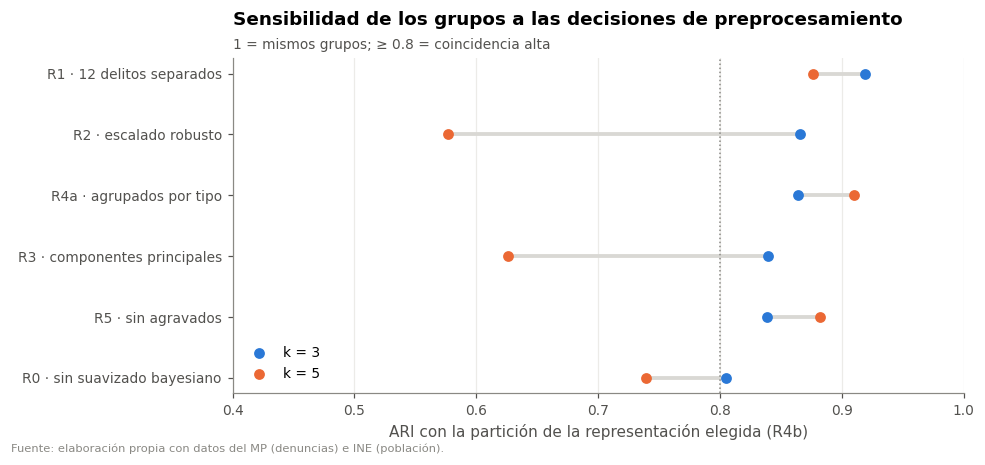

In [5]:
ALTERNATIVAS = {
    "R1 · 12 delitos separados": "R1_log_suavizada_standard",
    "R2 · escalado robusto": "R2_log_suavizada_robust",
    "R3 · componentes principales": "R3_pca",
    "R0 · sin suavizado bayesiano": "R0_log_observada_standard",
    "R4a · agrupados por tipo": "R4a_agrupada_por_tipo",
    "R5 · sin agravados": "R5_sin_agravados",
}
filas = []
for k in K_CANDIDATOS:
    ref = ajustar_kmeans(k)(X)
    for etiqueta, archivo in ALTERNATIVAS.items():
        Z = pd.read_csv(RUTA_PROCESSED / "matrices" / f"{archivo}.csv", index_col=0).values
        filas.append({"k": k, "alternativa": etiqueta,
                      "ARI_vs_R4b": adjusted_rand_score(ref, ajustar_kmeans(k)(Z))})
sensibilidad = pd.DataFrame(filas).pivot_table(index="alternativa", columns="k", values="ARI_vs_R4b",
                                               sort=False)
display(sensibilidad)

fig, ax = plt.subplots(figsize=(9, 4.2))
orden = sensibilidad[K_CANDIDATOS[0]].sort_values().index
for j, k in enumerate(K_CANDIDATOS):
    ax.scatter(sensibilidad.loc[orden, k], range(len(orden)), s=50, color=PALETA_CATEGORICA[j],
               label=f"k = {k}", zorder=3)
for i, a in enumerate(orden):
    ax.plot(sensibilidad.loc[a, K_CANDIDATOS], [i, i], color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.axvline(0.8, color=COLOR["gris"], linestyle=":", linewidth=1)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(0.4, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ARI con la partición de la representación elegida (R4b)")
ax.set_title("Sensibilidad de los grupos a las decisiones de preprocesamiento")
subtitulo(ax, "1 = mismos grupos; ≥ 0.8 = coincidencia alta")
ax.legend(loc="lower left")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "02_sensibilidad_preprocesamiento", CARPETA_FIG)
plt.show()

## 5. Estabilidad de cada grupo (Jaccard bootstrap)

La estabilidad global puede esconder grupos débiles. Siguiendo a Hennig (2007), se calcula para **cada grupo** el índice de **Jaccard** medio con su mejor equivalente en 100 remuestreos bootstrap:

- **≥ 0.75**: grupo estable.
- **0.60 – 0.75**: patrón real, pero con límites difusos.
- **< 0.50**: el grupo "se disuelve" al cambiar ligeramente los datos.

,3,4,5,6
G1,0.957,0.901,0.929,0.567
G2,0.949,0.518,0.804,0.561
G3,0.949,0.636,0.808,0.669
G4,NaN,0.826,0.795,0.748
G5,NaN,NaN,0.875,0.689
G6,NaN,NaN,NaN,0.870
mínimo,0.949,0.518,0.795,0.561


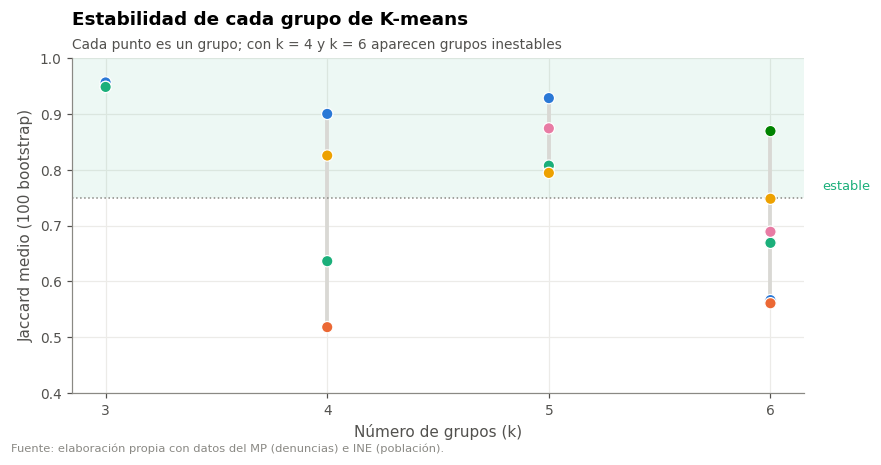

In [6]:
jaccard = {k: estabilidad_por_grupo(ajustar_kmeans(k), X, n_boot=100, semilla=SEMILLA) for k in range(3, 7)}
tabla_j = pd.DataFrame({k: pd.Series(v, index=[f"G{i}" for i in range(1, k + 1)]) for k, v in jaccard.items()})
tabla_j.loc["mínimo"] = tabla_j.min()
display(tabla_j)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axhspan(0.75, 1.0, color=COLOR["aqua"], alpha=0.08, lw=0)
ax.axhline(0.75, color=COLOR["gris"], linestyle=":", linewidth=1)
for k, v in jaccard.items():
    ax.scatter(np.full(len(v), k), v, s=55, color=[COLOR_GRUPO[i] for i in range(len(v))],
               edgecolor="white", linewidth=0.8, zorder=3)
    ax.plot([k, k], [v.min(), v.max()], color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.text(6.45, 0.765, "estable", fontsize=8.5, color=COLOR["aqua"], ha="right")
ax.set_xticks(list(jaccard))
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Jaccard medio (100 bootstrap)")
ax.set_ylim(0.4, 1.0)
ax.set_title("Estabilidad de cada grupo de K-means")
subtitulo(ax, "Cada punto es un grupo; con k = 4 y k = 6 aparecen grupos inestables")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "03_estabilidad_por_grupo", CARPETA_FIG)
plt.show()

## 6. ¿$k = 3$ o $k = 5$?

### 6.1 Métricas lado a lado

In [7]:
modelos_k = {k: KMeans(k, n_init=N_INIT_FINAL, random_state=SEMILLA).fit(X) for k in K_CANDIDATOS}
etiquetas_k = {k: ordenar_grupos(X, m.labels_) for k, m in modelos_k.items()}

filas = []
for k in K_CANDIDATOS:
    lab = etiquetas_k[k]
    m = metricas_internas(X, lab)
    est, _ = estabilidad_bootstrap(ajustar_kmeans(k), X, n_boot=100, semilla=SEMILLA)
    sil = silhouette_samples(X, lab)
    gmm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEMILLA).fit_predict(X)
    filas.append({"k": k, "silhouette": m["silhouette"], "davies_bouldin": m["davies_bouldin"],
                  "calinski_harabasz": m["calinski_harabasz"], "estabilidad global": est,
                  "Jaccard mínimo por grupo": jaccard[k].min(),
                  "% silueta negativa": (sil < 0).mean() * 100,
                  "grupo más pequeño": int(np.bincount(lab)[1:].min()),
                  "ARI con GMM (mismo k)": adjusted_rand_score(lab, gmm)})
lado_a_lado = pd.DataFrame(filas).set_index("k").T
display(lado_a_lado)

k,3,5
silhouette,0.232,0.175
davies_bouldin,1.388,1.613
calinski_harabasz,167.557,115.550
estabilidad global,0.922,0.798
Jaccard mínimo por grupo,0.949,0.795
% silueta negativa,0.588,2.353
grupo más pequeño,88.000,42.000
ARI con GMM (mismo k),0.881,0.759


### 6.2 ¿Los grupos difieren solo en **nivel** o también en **perfil**?

El centroide de cada grupo (en valores estandarizados) se descompone en:

- **Nivel:** el promedio de sus 10 variables (¿el grupo tiene más o menos incidencia en general?).
- **Perfil:** la desviación de cada variable respecto a ese promedio (¿qué delitos destacan *relativamente*?).

Si casi toda la diferencia entre grupos es de nivel, los grupos solo ordenan a los municipios de menor a mayor, sin distinguir **tipos** de criminalidad.

In [8]:
perfiles = {}
for k in K_CANDIDATOS:
    lab = etiquetas_k[k]
    centroides = pd.DataFrame([X[lab == g].mean(axis=0) for g in range(1, k + 1)],
                              index=[f"G{g}" for g in range(1, k + 1)], columns=X_df.columns)
    nivel = centroides.mean(axis=1)
    forma = centroides.sub(nivel, axis=0)
    pct_nivel = (nivel ** 2).sum() * X.shape[1] / (centroides ** 2).values.sum() * 100
    perfiles[k] = centroides
    print(f"k = {k}: el {pct_nivel:.0f} % de la diferencia entre grupos es de nivel "
          f"y el {100 - pct_nivel:.0f} % es de perfil.")

k = 3: el 85 % de la diferencia entre grupos es de nivel y el 15 % es de perfil.
k = 5: el 76 % de la diferencia entre grupos es de nivel y el 24 % es de perfil.


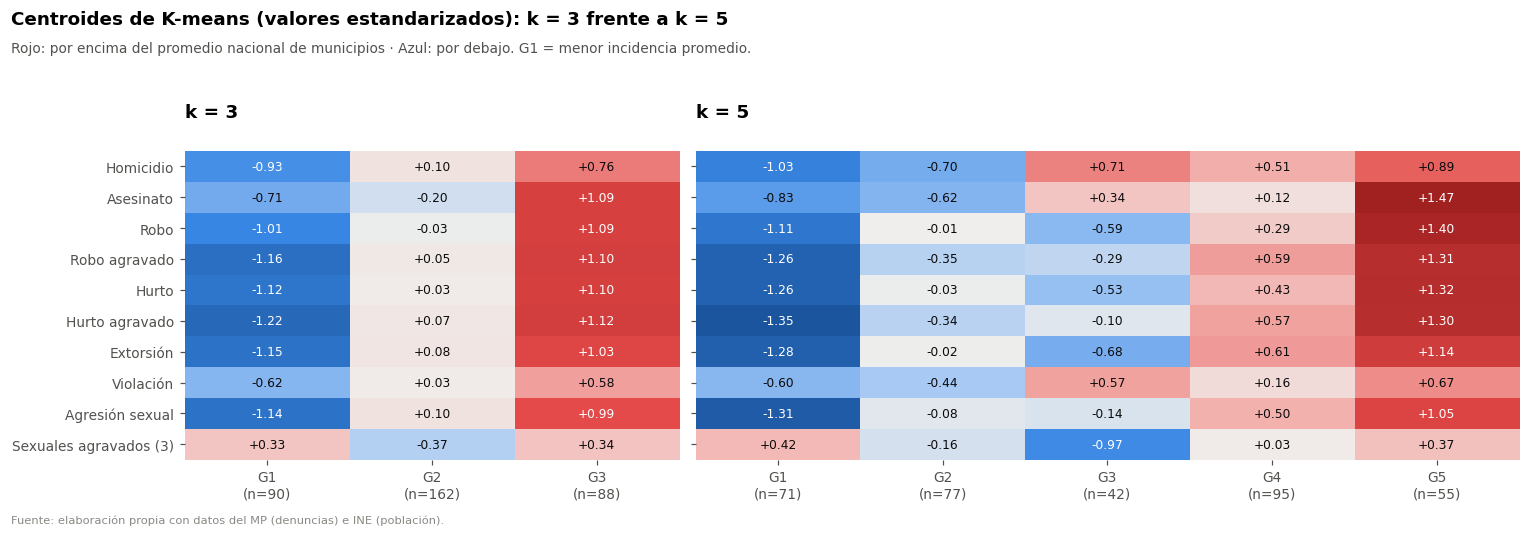

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [3, 5]})
for ax, k in zip(axes, K_CANDIDATOS):
    c = perfiles[k].T
    ax.imshow(c.values, cmap=CMAP_DIVERGENTE, vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(k), [f"G{g}\n(n={np.sum(etiquetas_k[k] == g)})" for g in range(1, k + 1)])
    ax.set_yticks(range(len(c)), [NOMBRES[v] for v in c.index])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(c.shape[0]):
        for j in range(c.shape[1]):
            v = c.values[i, j]
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.9 else COLOR["texto"])
    ax.set_title(f"k = {k}")
    if k != K_CANDIDATOS[0]:
        ax.set_yticklabels([])
fig.suptitle("Centroides de K-means (valores estandarizados): k = 3 frente a k = 5", x=0.01,
             ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.9, "Rojo: por encima del promedio nacional de municipios · Azul: por debajo. "
         "G1 = menor incidencia promedio.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
guardar_figura(fig, "04_centroides_k3_vs_k5", CARPETA_FIG)
plt.show()

### 6.3 ¿De dónde salen los grupos de $k = 5$?

In [10]:
anidamiento = pd.crosstab(pd.Series(etiquetas_k[5], name="k = 5"), pd.Series(etiquetas_k[3], name="k = 3"))
anidamiento.index = [f"G{g}" for g in anidamiento.index]
anidamiento.columns = [f"G{g}" for g in anidamiento.columns]
display(anidamiento)

base = pd.read_csv(RUTA_PROCESSED / "base_municipal_2022_2025.csv", encoding="utf-8-sig").set_index("Codigo_Municipio")
contexto = base.loc[X_df.index].assign(grupo=etiquetas_k[5])
resumen_ctx = contexto.groupby("grupo").agg(
    municipios=("Municipio", "size"),
    poblacion_mediana=("Poblacion_prom", "median"),
    tasa_total_mediana=("Tasa_total", "median"),
    departamentos_frecuentes=("Departamento", lambda s: ", ".join(
        f"{d} ({n})" for d, n in s.value_counts().head(3).items())),
)
resumen_ctx.index = [f"G{g}" for g in resumen_ctx.index]
display(resumen_ctx)

,G1,G2,G3
G1,71,0,0
G2,13,64,0
G3,6,36,0
G4,0,62,33
G5,0,0,55


,municipios,poblacion_mediana,tasa_total_mediana,departamentos_frecuentes
G1,71,"42,310.500",92.112,"Huehuetenango (25), Quiché (15), San Marcos (8)"
G2,77,"24,473.750",227.103,"San Marcos (14), Sololá (11), Chimaltenango (8)"
G3,42,"33,546.625",207.949,"Petén (10), Chiquimula (7), Zacapa (5)"
G4,95,"27,480.250",415.599,"Jutiapa (13), Suchitepéquez (12), Sacatepéquez..."
G5,55,"57,686.500",893.585,"Guatemala (13), Escuintla (11), Sacatepéquez (5)"


### 6.4 Regla de decisión para $k$

Una vez que la partición cumple estándares mínimos de calidad, se prefiere la **más informativa** para el objetivo 3 del protocolo (*caracterizar cada conglomerado según los patrones predominantes*). La regla es:

1. **Umbrales de calidad:** estabilidad global ≥ 0.75, Jaccard **de cada grupo** ≥ 0.75, silueta negativa ≤ 5 % y grupo más pequeño ≥ 5 % de los municipios (17).
2. **Entre los $k$ que cumplen**, elegir el **mayor**, porque distingue más patrones.

In [11]:
filas = []
for k in range(3, 7):
    ajustar = ajustar_kmeans(k)
    lab = ordenar_grupos(X, ajustar(X))
    m = metricas_internas(X, lab)
    est, _ = estabilidad_bootstrap(ajustar, X, n_boot=100, semilla=SEMILLA)
    sil = silhouette_samples(X, lab)
    cumple = (est >= 0.75) and (jaccard[k].min() >= 0.75) and ((sil < 0).mean() <= 0.05) \
        and (np.bincount(lab)[1:].min() >= 17)
    filas.append({"k": k, "silhouette": m["silhouette"], "estabilidad global": est,
                  "Jaccard mínimo": jaccard[k].min(), "% silueta negativa": (sil < 0).mean() * 100,
                  "grupo más pequeño": int(np.bincount(lab)[1:].min()), "cumple": cumple})
regla = pd.DataFrame(filas).set_index("k")
display(regla)
K_FINAL = int(regla[regla["cumple"]].index.max())
print(f"k final: {K_FINAL}")

,silhouette,estabilidad global,Jaccard mínimo,% silueta negativa,grupo más pequeño,cumple
k,,,,,,
3,0.232,0.922,0.949,0.588,88,True
4,0.216,0.642,0.518,1.471,52,False
5,0.175,0.798,0.795,1.765,42,True
6,0.154,0.645,0.561,3.529,34,False


k final: 5


### 6.5 ¿Y $k = 2$?

La regla anterior parte de $k \ge 3$ (criterio del notebook 05). Sin embargo, $k = 2$ tiene la **mejor Silhouette** de todo el barrido, así que conviene mostrar explícitamente que fue considerado y **qué información se pierde** con él.

Para medir esa pérdida se usa el **η² (eta cuadrado)** de cada delito: la proporción de su variación entre municipios que queda explicada por el grupo al que pertenecen ($\eta^2 = SS_{entre} / SS_{total}$). Un η² bajo significa que la partición **no distingue** a los municipios en ese delito.

In [12]:
modelo_k2 = KMeans(2, n_init=N_INIT_FINAL, random_state=SEMILLA).fit(X)
etiquetas_k[2] = ordenar_grupos(X, modelo_k2.labels_)
m2 = metricas_internas(X, etiquetas_k[2])
est2, _ = estabilidad_bootstrap(ajustar_kmeans(2), X, n_boot=100, semilla=SEMILLA)
jac2 = estabilidad_por_grupo(ajustar_kmeans(2), X, n_boot=100, semilla=SEMILLA)
sil2 = silhouette_samples(X, etiquetas_k[2])
centroides_k2 = pd.DataFrame([X[etiquetas_k[2] == g].mean(axis=0) for g in (1, 2)],
                             index=["G1", "G2"], columns=X_df.columns)
nivel2 = centroides_k2.mean(axis=1)
pct_nivel2 = (nivel2 ** 2).sum() * X.shape[1] / (centroides_k2 ** 2).values.sum() * 100

k2_resumen = pd.Series({
    "silhouette": m2["silhouette"], "davies_bouldin": m2["davies_bouldin"],
    "calinski_harabasz": m2["calinski_harabasz"], "estabilidad global": est2,
    "Jaccard mínimo por grupo": jac2.min(), "% silueta negativa": (sil2 < 0).mean() * 100,
    "tamaños": " / ".join(map(str, np.bincount(etiquetas_k[2])[1:])),
    "% diferencia de nivel": pct_nivel2,
}, name="k = 2")
display(k2_resumen.to_frame())
display(centroides_k2.rename(columns=NOMBRES).T.round(2))

,k = 2
silhouette,0.306
davies_bouldin,1.217
calinski_harabasz,206.719
estabilidad global,0.846
Jaccard mínimo por grupo,0.914
% silueta negativa,0.294
tamaños,139 / 201
% diferencia de nivel,84.826


,G1,G2
Homicidio,-0.780,0.540
Asesinato,-0.630,0.440
Robo,-0.750,0.520
Robo agravado,-0.910,0.630
Hurto,-0.810,0.560
Hurto agravado,-0.930,0.640
Extorsión,-0.850,0.590
Violación,-0.460,0.320
Agresión sexual,-0.800,0.550
Sexuales agravados (3),0.090,-0.060


,k = 2,k = 3,k = 5
Homicidio,42.100,38.100,59.700
Asesinato,27.600,45.600,59.800
Robo,38.600,57.400,64.200
Robo agravado,56.800,67.300,74.100
Hurto,45.500,64.300,70.100
Hurto agravado,59.600,71.900,77.500
Extorsión,50.100,62.400,71.100
Violación,14.400,18.800,24.000
Agresión sexual,44.300,60.500,61.100
Sexuales agravados (3),0.600,12.400,18.100


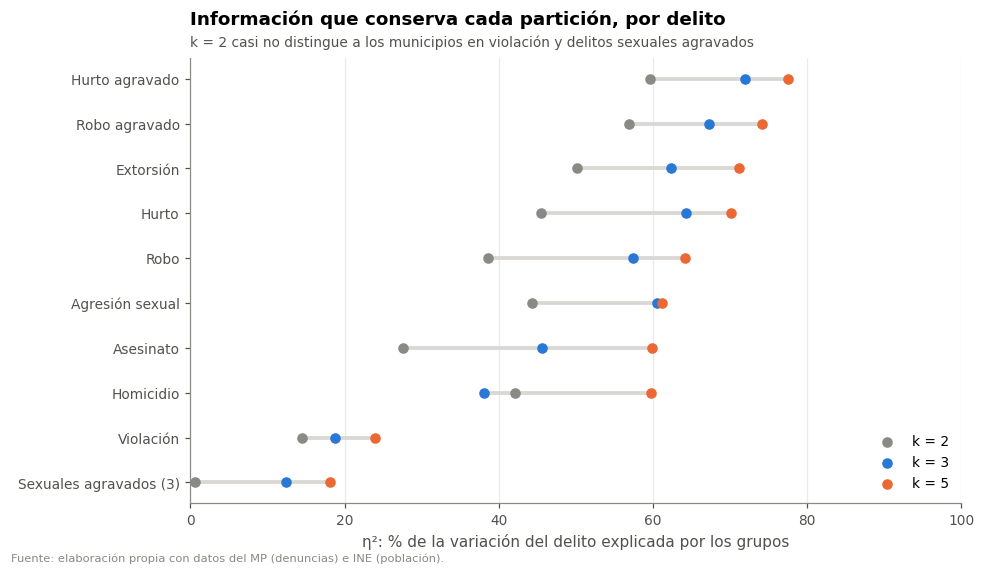

In [13]:
def eta_cuadrado(X, lab):
    """η² por variable: varianza entre grupos / varianza total."""
    total = ((X - X.mean(axis=0)) ** 2).sum(axis=0)
    entre = sum((lab == g).sum() * (X[lab == g].mean(axis=0) - X.mean(axis=0)) ** 2 for g in np.unique(lab))
    return entre / total

eta = pd.DataFrame({f"k = {k}": eta_cuadrado(X, etiquetas_k[k]) for k in [2, 3, 5]},
                   index=[NOMBRES[c] for c in X_df.columns])
eta.loc["Promedio (10 variables)"] = eta.mean()
display((eta * 100).round(1))

orden = eta.drop("Promedio (10 variables)")["k = 5"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.2))
for j, col in enumerate(["k = 2", "k = 3", "k = 5"]):
    ax.scatter(eta.loc[orden, col] * 100, range(len(orden)), s=48, zorder=3,
               color=[COLOR["gris"], COLOR["azul"], COLOR["naranja"]][j], label=col)
for i, d in enumerate(orden):
    ax.plot([eta.loc[d, ["k = 2", "k = 3", "k = 5"]].min() * 100,
             eta.loc[d, ["k = 2", "k = 3", "k = 5"]].max() * 100], [i, i],
            color=COLOR["gris_claro"], linewidth=2.5, zorder=1)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("η²: % de la variación del delito explicada por los grupos")
ax.set_title("Información que conserva cada partición, por delito")
subtitulo(ax, "k = 2 casi no distingue a los municipios en violación y delitos sexuales agravados")
ax.legend(loc="lower right")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "06_eta2_k2_k3_k5", CARPETA_FIG)
plt.show()

In [14]:
cruce_25 = pd.crosstab(pd.Series(etiquetas_k[5], name="k = 5"), pd.Series(etiquetas_k[2], name="k = 2"))
cruce_25.index = [f"G{g}" for g in cruce_25.index]
cruce_25.columns = [f"G{g}" for g in cruce_25.columns]
display(cruce_25)
g3_k2 = cruce_25.loc["G3"]
print(f"El perfil de violencia contra las personas (G3 de k = 5, {g3_k2.sum()} municipios) queda "
      f"repartido: {g3_k2['G1']} en el G1 y {g3_k2['G2']} en el G2 de k = 2.")

,G1,G2
G1,71,0
G2,50,27
G3,18,24
G4,0,95
G5,0,55


El perfil de violencia contra las personas (G3 de k = 5, 42 municipios) queda repartido: 18 en el G1 y 24 en el G2 de k = 2.


**Lectura:** $k = 2$ separa con claridad (Silhouette ≈ 0.31) municipios de **baja** y **alta** incidencia. Esa separación es casi solo de **nivel**: los dos centroides son prácticamente imágenes especulares en todos los delitos. Por eso tiene la mejor Silhouette: dividir un continuo por la mitad siempre produce grupos compactos.

Lo que pierde es precisamente lo que el objetivo 3 del protocolo necesita:

- **Explica menos de la variación de los delitos:** en promedio, un η² de **38 %** frente a 50 % con $k = 3$ y **58 %** con $k = 5$.
- **No distingue tipos de criminalidad.** El η² de violación es de 14 % (24 % con $k = 5$) y el de delitos sexuales agravados de **0.6 %** (18 % con $k = 5$): con $k = 2$ esa variable no aporta nada a la partición.
- **Hace desaparecer el perfil de violencia contra las personas** (G3 de $k = 5$): sus 42 municipios quedan repartidos entre los dos grupos (18 y 24).
- Su estabilidad (0.85) es **menor** que la de $k = 3$ (0.92), así que tampoco gana en robustez.

Se conserva como **referencia**: es la partición con mejor separación geométrica, pero es la menos informativa.

### 6.6 ¿Sigue siendo K-means el mejor algoritmo con $k = 5$?

La comparación formal de los tres algoritmos (notebook 06, objetivo específico 1) se hizo con $k = 3$, el valor que los tres eligieron con la regla común. Como el modelo final usa $k = 5$, hay que comprobar que **el ganador no cambia** en ese escenario. Si otro algoritmo fuera mejor con $k = 5$, habría que preferirlo.

Se comparan los tres con la misma configuración del notebook 06 y los mismos criterios, más la estabilidad **de cada grupo** (sección 5).

In [15]:
CONSTRUCTORES_06 = {
    "K-means": lambda k: (lambda Z: KMeans(k, n_init=N_INIT, random_state=SEMILLA).fit_predict(Z)),
    "GMM (diag)": lambda k: (lambda Z: GaussianMixture(k, covariance_type="diag", n_init=5,
                                                       random_state=SEMILLA).fit_predict(Z)),
    "Spectral": lambda k: (lambda Z: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=10,
                                                        random_state=SEMILLA).fit_predict(Z)),
}
filas, etiquetas_alg = [], {}
for k in K_CANDIDATOS:
    for alg, ctor in CONSTRUCTORES_06.items():
        ajustar = ctor(k)
        lab = ajustar(X)
        etiquetas_alg[(alg, k)] = lab
        m = metricas_internas(X, lab)
        est, _ = estabilidad_bootstrap(ajustar, X, n_boot=100, semilla=SEMILLA)
        jac = estabilidad_por_grupo(ajustar, X, n_boot=100, semilla=SEMILLA)
        filas.append({"k": k, "algoritmo": alg, "silhouette": m["silhouette"],
                      "davies_bouldin": m["davies_bouldin"], "calinski_harabasz": m["calinski_harabasz"],
                      "estabilidad global": est, "Jaccard mínimo por grupo": jac.min(),
                      "% silueta negativa": (silhouette_samples(X, lab) < 0).mean() * 100,
                      "grupo más pequeño": int(np.bincount(lab).min())})
comp_k = pd.DataFrame(filas)
for k in K_CANDIDATOS:
    d = comp_k[comp_k["k"] == k].set_index("algoritmo").drop(columns="k")
    pos = pd.DataFrame({
        "silhouette": d["silhouette"].rank(ascending=False),
        "davies_bouldin": d["davies_bouldin"].rank(),
        "calinski_harabasz": d["calinski_harabasz"].rank(ascending=False),
        "estabilidad global": d["estabilidad global"].rank(ascending=False),
        "Jaccard mínimo por grupo": d["Jaccard mínimo por grupo"].rank(ascending=False),
        "% silueta negativa": d["% silueta negativa"].rank(),
    })
    d["posición media"] = pos.mean(axis=1)
    print(f"k = {k}")
    display(d.sort_values("posición media"))
comp_k.to_csv(RAIZ_PROY / "outputs" / "reports" / "07_comparacion_algoritmos_k3_k5.csv",
              index=False, encoding="utf-8-sig")

concordancia5 = pd.DataFrame([[adjusted_rand_score(etiquetas_alg[(a, 5)], etiquetas_alg[(b, 5)])
                               for b in CONSTRUCTORES_06] for a in CONSTRUCTORES_06],
                             index=list(CONSTRUCTORES_06), columns=list(CONSTRUCTORES_06))
print("Concordancia entre algoritmos con k = 5 (ARI)")
display(concordancia5.round(2))

k = 3


,silhouette,davies_bouldin,calinski_harabasz,estabilidad global,Jaccard mínimo por grupo,% silueta negativa,grupo más pequeño,posición media
algoritmo,,,,,,,,
K-means,0.232,1.388,167.557,0.922,0.949,0.588,88,1.167
Spectral,0.232,1.268,157.261,0.878,0.892,10.588,67,2.333
GMM (diag),0.228,1.399,165.248,0.879,0.891,3.529,88,2.500


k = 5


,silhouette,davies_bouldin,calinski_harabasz,estabilidad global,Jaccard mínimo por grupo,% silueta negativa,grupo más pequeño,posición media
algoritmo,,,,,,,,
K-means,0.175,1.611,115.536,0.798,0.795,1.765,42,1.167
GMM (diag),0.164,1.676,110.765,0.805,0.758,8.529,40,2.333
Spectral,0.169,1.660,109.833,0.607,0.554,7.941,43,2.500


Concordancia entre algoritmos con k = 5 (ARI)


,K-means,GMM (diag),Spectral
K-means,1.000,0.740,0.710
GMM (diag),0.740,1.000,0.590
Spectral,0.710,0.590,1.000


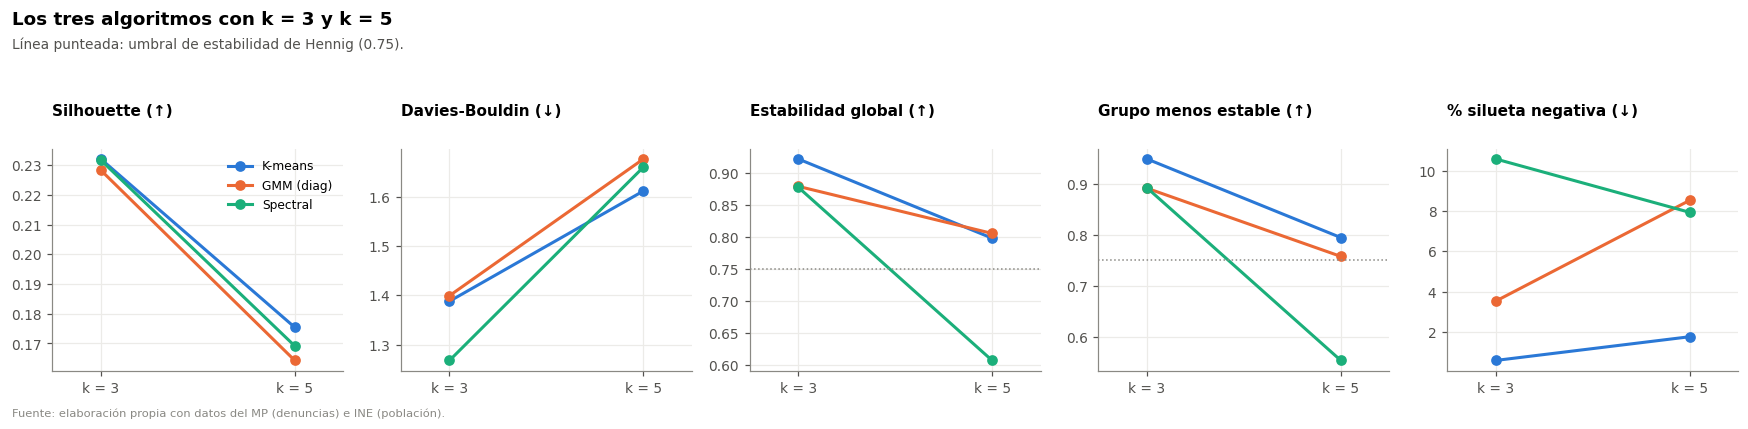

In [16]:
metricas_fig = [("silhouette", "Silhouette (↑)"), ("davies_bouldin", "Davies-Bouldin (↓)"),
                ("estabilidad global", "Estabilidad global (↑)"), ("Jaccard mínimo por grupo", "Grupo menos estable (↑)"),
                ("% silueta negativa", "% silueta negativa (↓)")]
colores_alg = {"K-means": PALETA_CATEGORICA[0], "GMM (diag)": PALETA_CATEGORICA[1], "Spectral": PALETA_CATEGORICA[2]}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, (col, titulo) in zip(axes, metricas_fig):
    for alg in CONSTRUCTORES_06:
        d = comp_k[comp_k["algoritmo"] == alg]
        ax.plot(d["k"], d[col], marker="o", color=colores_alg[alg], label=alg)
    if col in ("estabilidad global", "Jaccard mínimo por grupo"):
        ax.axhline(0.75, color=COLOR["gris"], linestyle=":", linewidth=1)
    ax.set_xticks(K_CANDIDATOS, [f"k = {k}" for k in K_CANDIDATOS])
    ax.set_xlim(2.5, 5.5)
    ax.set_title(titulo, fontsize=10)
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Los tres algoritmos con k = 3 y k = 5", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.89, "Línea punteada: umbral de estabilidad de Hennig (0.75).", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.88))
guardar_figura(fig, "07_algoritmos_k3_k5", CARPETA_FIG)
plt.show()

**Por qué K-means es el modelo final (también con $k = 5$):**

1. **Mejor calidad geométrica en ambos escenarios.** Con $k = 5$ tiene la mejor Silhouette, el mejor Davies-Bouldin y el mejor Calinski-Harabasz de los tres.
2. **Ningún grupo débil.** Es el único con $k = 5$ en que **todos** los grupos superan el umbral de estabilidad de 0.75 (Jaccard mínimo ≈ 0.80). El GMM queda justo en el límite con su grupo menos estable, y Spectral tiene grupos que se disuelven (≈ 0.56).
3. **Menos municipios mal asignados:** menos del 2 % con silueta negativa, frente a cerca del 8 % en GMM y Spectral.
4. **La estabilidad global empata con el GMM** (≈ 0.80 frente a ≈ 0.81, diferencia menor que su variación entre remuestreos). No es un argumento a favor de ninguno de los dos.
5. **Interpretabilidad y reproducibilidad.** Cada grupo tiene un **centroide** que se lee directamente como su perfil (base de la caracterización del notebook 08). Con `n_init = 500` y semilla fija, la solución es la misma en cualquier ejecución. El GMM diagonal, en cambio, supone que los delitos son independientes dentro de cada grupo, algo que las correlaciones del notebook 03 contradicen.

En resumen, el ranking del objetivo 1 **se mantiene** al pasar de $k = 3$ a $k = 5$. K-means no se eligió en un escenario para usarse en otro: es el mejor en los dos.

## 7. Modelo final

Se ajusta K-means con la configuración optimizada y se guardan, para cada municipio: el grupo final ($k$ elegido), el grupo con $k = 3$ (nivel agregado), la silueta y la distancia al centroide.

In [17]:
modelo_final = KMeans(K_FINAL, init="k-means++", n_init=N_INIT_FINAL, random_state=SEMILLA).fit(X)
grupo_final = ordenar_grupos(X, modelo_final.labels_)
m_final = metricas_internas(X, grupo_final)

# Centroides en el orden de los grupos (G1 = menor incidencia)
mapa = {orig: nuevo for orig, nuevo in zip(modelo_final.labels_, grupo_final)}
centroides_final = pd.DataFrame(
    [modelo_final.cluster_centers_[[o for o, n in mapa.items() if n == g][0]] for g in range(1, K_FINAL + 1)],
    index=[f"G{g}" for g in range(1, K_FINAL + 1)], columns=X_df.columns)

resultado = pd.DataFrame({
    "Departamento": base.loc[X_df.index, "Departamento"],
    "Municipio": base.loc[X_df.index, "Municipio"],
    "grupo": grupo_final,
    "grupo_k3": etiquetas_k[3],
    "grupo_k2": etiquetas_k[2],
    "silueta": silhouette_samples(X, grupo_final),
    "distancia_centroide": np.linalg.norm(X - centroides_final.values[grupo_final - 1], axis=1),
}, index=X_df.index)

resultado.to_csv(RUTA_PROCESSED / "resultado_agrupamiento.csv", encoding="utf-8-sig")
centroides_final.to_csv(RUTA_REPORTES / "07_centroides_finales.csv", encoding="utf-8-sig")

final = {
    "algoritmo": "K-means",
    "k": K_FINAL,
    "init": "k-means++",
    "n_init": N_INIT_FINAL,
    "random_state": SEMILLA,
    "representacion": dec06["representacion"],
    "silhouette": round(m_final["silhouette"], 4),
    "davies_bouldin": round(m_final["davies_bouldin"], 4),
    "calinski_harabasz": round(m_final["calinski_harabasz"], 2),
    "estabilidad_global": round(float(regla.loc[K_FINAL, "estabilidad global"]), 4),
    "jaccard_por_grupo": [round(float(v), 3) for v in jaccard[K_FINAL]],
    "tamanos": [int(n) for n in np.bincount(grupo_final)[1:]],
}
with open(RUTA_REPORTES / "07_modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(final, f, ensure_ascii=False, indent=2)
print(json.dumps(final, ensure_ascii=False, indent=2))

{
  "algoritmo": "K-means",
  "k": 5,
  "init": "k-means++",
  "n_init": 500,
  "random_state": 42,
  "representacion": "R4b_agravados_agrupados",
  "silhouette": 0.175,
  "davies_bouldin": 1.6135,
  "calinski_harabasz": 115.55,
  "estabilidad_global": 0.798,
  "jaccard_por_grupo": [
    0.929,
    0.804,
    0.808,
    0.795,
    0.875
  ],
  "tamanos": [
    71,
    77,
    42,
    95,
    55
  ]
}


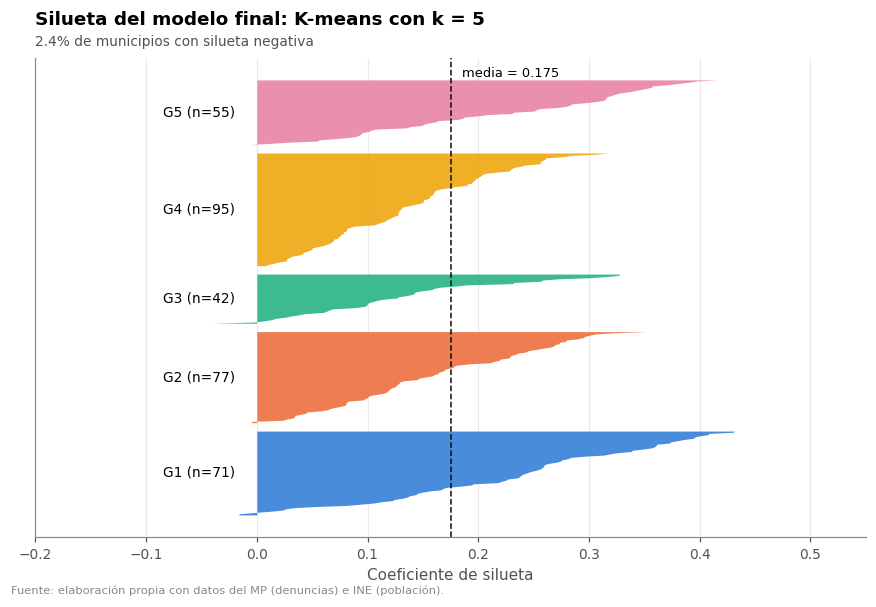

In [18]:
sil = resultado["silueta"].values
fig, ax = plt.subplots(figsize=(8, 5.5))
y = 0
for g in range(1, K_FINAL + 1):
    v = np.sort(sil[grupo_final == g])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, color=COLOR_GRUPO[g - 1], alpha=0.85, lw=0)
    ax.text(-0.02, y + len(v) / 2, f"G{g} (n={len(v)})", ha="right", va="center", fontsize=9)
    y += len(v) + 6
ax.axvline(sil.mean(), color=COLOR["texto"], linestyle="--", linewidth=1)
ax.text(sil.mean() + 0.01, y - 4, f"media = {sil.mean():.3f}", fontsize=8.5)
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlim(-0.2, 0.55)
ax.set_xlabel("Coeficiente de silueta")
ax.set_title(f"Silueta del modelo final: K-means con k = {K_FINAL}")
subtitulo(ax, f"{(sil < 0).mean():.1%} de municipios con silueta negativa")
fuente(fig, FUENTE)
fig.tight_layout()
guardar_figura(fig, "05_silueta_modelo_final", CARPETA_FIG)
plt.show()

## 8. Conclusiones

**Hiperparámetros**

- La inicialización `k-means++` es igual o mejor que la aleatoria. Con $k = 3$ basta con 50 reinicios para llegar siempre a la misma solución.
- Con $k = 5$ existen **varios mínimos locales casi equivalentes**. Con 50 reinicios la partición varía ligeramente entre semillas (ARI ≥ 0.91); con **500 reinicios** es prácticamente idéntica (ARI ≥ 0.99). El modelo final usa `k-means++`, `n_init = 500` y semilla 42, lo que lo hace **reproducible**.

**Variante robusta**

- K-medoids (euclidiana y Manhattan) es **peor en todas las métricas** y menos estable (0.56–0.71 frente a 0.80–0.92). Como el suavizado y el logaritmo ya controlaron los extremos, la robustez adicional no aporta. Se **mantiene K-means**, y K-medoids queda documentado como alternativa evaluada.

**Sensibilidad al preprocesamiento**

- Con $k = 3$ los grupos son **muy robustos**: ARI de 0.81 a 0.92 frente a todas las decisiones alternativas.
- Con $k = 5$ la partición se mantiene frente a cómo se tratan los delitos agravados (ARI de 0.88 a 0.91) y frente a no suavizar (0.74). Es **más sensible** al escalado robusto (0.58) y al PCA (0.63), porque ambos cambian el peso relativo de las variables. Es una **limitación** que conviene declarar.

**¿$k = 3$ o $k = 5$?**

| Criterio | $k = 3$ | $k = 5$ |
|---|---|---|
| Silhouette | **0.232** | 0.175 |
| Estabilidad global | **0.92** | 0.80 |
| Jaccard mínimo por grupo | **0.95** | 0.80 |
| Silueta negativa | **0.6 %** | 2.4 % |
| Diferencia de **perfil** entre grupos | 15 % | **24 %** |
| Coincidencia con GMM | **0.88** | 0.76 |

- $k = 3$ tiene mejores métricas, pero sus grupos solo ordenan a los municipios por **nivel** (bajo, medio, alto: el 85 % de la diferencia es de nivel).
- $k = 5$ cumple **todos los umbrales de calidad** y revela un patrón que $k = 3$ escondía: el **G3** (42 municipios, sobre todo de Petén, Chiquimula y Zacapa) tiene **homicidio y violación altos** pero **delitos patrimoniales y extorsión bajos**, un perfil de **violencia contra las personas** distinto al de las zonas urbanas.
- $k = 4$ y $k = 6$ **no cumplen**: tienen grupos que se disuelven (Jaccard de 0.52 y 0.56).
- **$k = 2$ fue considerado** y tiene la mejor Silhouette (0.31), pero solo separa baja y alta incidencia (85 % de la diferencia es de nivel). Explica en promedio el 38 % de la variación de los delitos (frente a 58 % con $k = 5$), prácticamente nada de los delitos sexuales agravados (η² 0.6 %), hace desaparecer el perfil de violencia contra las personas y es menos estable que $k = 3$ (0.85 frente a 0.92). Se conserva como referencia.
- Además, los grupos de $k = 5$ están casi **anidados** en los de $k = 3$: el G1 de $k = 5$ es el núcleo del grupo bajo, el G5 el núcleo del grupo alto, y el grupo medio de $k = 3$ se divide en perfiles distintos.

**Algoritmo con $k = 5$:** el ranking del notebook 06 se mantiene. K-means tiene la mejor Silhouette, Davies-Bouldin y Calinski-Harabasz, es el único con todos sus grupos estables (Jaccard ≥ 0.75) y tiene la menor proporción de municipios mal asignados. Solo empata con el GMM en estabilidad global (sección 6.6).

**Decisión:**

- **Modelo principal:** K-means, $k = 5$, `k-means++`, `n_init = 500`, sobre la representación **R4b** (12 delitos, con los 3 sexuales agravados consolidados).
- **$k = 3$:** análisis de sensibilidad y representación agregada (baja, media, alta), guardada como `grupo_k3`.
- **$k = 2$:** referencia de máxima separación geométrica, descartada por su baja informatividad.

La validación definitiva de $k = 5$ se hace en el notebook 08: se comprobará si los perfiles se sostienen con tasas observadas, diferencias estadísticas y composición territorial.

**Modelo final:** K-means, $k = 5$, `k-means++`, `n_init = 500`, semilla 42 · Silhouette 0.175 · Davies-Bouldin 1.61 · Calinski-Harabasz 115.6 · estabilidad 0.80 · todos los grupos con Jaccard ≥ 0.795.